# GARCH en derivados: portafolio AAPL, oro, WTI, Euro FX y Nasdaq-100

**Proyecto de Productos Derivados · María Tamara López Romo, Daniel Alejandro Sánchez Aguirre, Michel Alexander Meléndez Salas**

Este notebook aplica la metodología de *GARCH en derivados* a las posiciones de nuestro proyecto:

| Posición del equipo | Origen | Subyacente |
|---|---|---|
| Call americana AAPL 345, vence 18-dic-2026 | Tarea 5; ejecutada en Investopedia a USD 13.50 | Acción AAPL |
| Bull Call Spread AAPL 345/355, vence 18-dic-2026 | Tarea 5, sección 6.3 | Acción AAPL |
| Bull Call Spread oro 4190/4400 | Abierto con Bloomberg OVML (14-oct-2026); settle CME del 27-oct-2026 | Futuro GCZ6 |
| Bear Put Spread WTI 91.5/85 | Abierto con Bloomberg OVML (14-oct-2026); settle CME del 27-oct-2026 | Futuro CLZ6 |
| Straddle Euro FX 1.115, vence 4-dic-2026 | CME Group, 28-oct-2026 | Futuro 6EZ6 |
| Cobertura con futuros E-mini Nasdaq-100 | CME Group, 27-oct-2026 (NQZ6 en 29,820.50) | Futuro NQZ6 |

| Sección de Hull (11.ª ed.) | Qué hace este notebook |
|---|---|
| 23.1 Estimating volatility | Volatilidad histórica con ventana móvil |
| 23.2 EWMA | Volatilidad con pesos exponenciales (λ = 0.94) |
| 23.3 y 23.5 GARCH(1,1) y máxima verosimilitud | Estimación de ω, α y β por activo |
| 23.4 Choosing between the models | Log-verosimilitud, AIC/BIC y Ljung-Box |
| 23.6 Using GARCH(1,1) to forecast | Volatilidad promedio durante la vida de cada opción |
| 23.7 y 23.8 Correlations | Matriz de correlación EWMA y VaR del portafolio de USD 1 millón |
| 22.6 Monte Carlo simulation | Trayectorias con GARCH y choques correlacionados |
| 22.8 Back testing | Prueba de Kupiec del VaR |
| Cap. 13 y 18 (árboles y opciones sobre futuros) | Valuación de cada pata con árbol CRR usando la volatilidad de GARCH |

**Cómo correrlo:** en Google Colab, *Entorno de ejecución → Ejecutar todo*. Si Yahoo Finance no responde, el código usa
datos **simulados** y lo avisa. Al final se genera `resultados_garch.json`, que alimenta el dashboard web.
Material educativo: no es una recomendación de inversión.

In [1]:
# ---- Instalación de paquetes (solo si faltan) ----
import subprocess, sys

def _pip(*pkgs):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pkgs])

for _mod, _pkg in [("yfinance", "yfinance"), ("arch", "arch"), ("statsmodels", "statsmodels")]:
    try:
        __import__(_mod)
    except ImportError:
        _pip(_pkg)

## 0. Parámetros del proyecto
Todo lo que el equipo debe actualizar está en esta celda. Los valores marcados con **ACTUALIZAR** vienen de capturas
anteriores y conviene refrescarlos el día de la entrega (TradingView, CME o Bloomberg).

In [2]:
import os, json, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize, brentq
from scipy.signal import lfilter
from scipy.stats import norm, chi2

# ---------------- Activos ----------------
# nombre -> ticker de Yahoo Finance. GC=F, CL=F y 6E=F son series continuas del futuro más cercano.
ACTIVOS = {"AAPL": "AAPL", "Oro": "GC=F", "WTI": "CL=F", "EURUSD": "6E=F", "NQ": "NQ=F"}
ES_FUTURO = {"AAPL": False, "Oro": True, "WTI": True, "EURUSD": True, "NQ": True}
PORTAFOLIO = ["AAPL", "Oro", "WTI"]          # activos del portafolio de USD 1 millón (agreguen "NQ" para incluirlo)
MULT_NQ = 20                                 # E-mini Nasdaq-100: USD 20 por punto del índice
COBERTURA_NQ = "AAPL"                        # posición del portafolio que se cubre con futuros NQ
INVERSION = 1_000_000
YEARS = 5
COLORES = {"AAPL": "#1f4e79", "Oro": "#b8860b", "WTI": "#8b2e2e", "EURUSD": "#2e6b4f", "NQ": "#5b4b8a"}

# ---------------- Mercado ----------------
# Tasa libre de riesgo: la misma de las tareas anteriores (3.892%). CME FedWatch (27-oct-2026) muestra el rango
# objetivo actual en 3.75%-4.00% (punto medio 3.875%) y 84.5% de probabilidad de alza el 9-dic-2026.
R_FREE = 0.03892
FEDWATCH = {"fecha": "2026-10-27", "rango_actual": "3.75%-4.00%",
            "prob": {"3.75%-4.00%": 0.155, "4.00%-4.25%": 0.789, "4.25%-4.50%": 0.055}}
DIV_YIELD = {"AAPL": 0.0}                    # escenario base de la Tarea 5 (q = 0)
MU_ANUAL = {"AAPL": 0.08, "Oro": 0.05, "WTI": 0.0, "EURUSD": 0.0, "NQ": 0.08}   # rendimiento esperado SUPUESTO (mundo real)

HORIZON_DAYS = 126       # pronóstico de precio: ~6 meses hábiles
N_SIM = 5000
LAMBDA_EWMA = 0.94
SEED = 123
UMBRAL_SENAL = 0.10      # 10% de diferencia entre GARCH y la volatilidad implícita
N_ARBOL = 500

# Precios de respaldo si no hay datos (última captura de cada fuente)
FALLBACK_PRICE = {"AAPL": 343.91, "Oro": 4164.45, "WTI": 92.90, "EURUSD": 1.115, "NQ": 29820.50}   # NQZ6: CME, 27-oct-2026

# ---------------- Posiciones del equipo (una fila por pata) ----------------
# pos: +1 compra, -1 venta. iv: volatilidad implícita de la pata. prima: precio pagado o recibido por unidad.
# Si prima es None se estima con el árbol a la volatilidad implícita; si iv es None se despeja de la prima.
POSICIONES = [
    # Tarea 5: TradingView 26-oct-2026 (IV 27.17%; IV del strike 355 = 25.88%).
    # Investopedia: orden ejecutada, 1 contrato a USD 13.50 (Holdings, 28-oct-2026: valor USD 1,315, resultado -USD 35).
    dict(estrategia="AAPL Call 345", activo="AAPL", tipo="call", K=345, venc="2026-12-18", pos=+1, iv=0.2717, prima=13.50, mult=100),
    dict(estrategia="AAPL Bull Call 345/355", activo="AAPL", tipo="call", K=345, venc="2026-12-18", pos=+1, iv=0.2717, prima=13.50, mult=100),
    dict(estrategia="AAPL Bull Call 345/355", activo="AAPL", tipo="call", K=355, venc="2026-12-18", pos=-1, iv=0.2588, prima=None, mult=100),
    # Oro y WTI: se abrieron con los precios de Bloomberg OVML del 14-oct-2026 (prima = precio pagado o recibido).
    # La volatilidad de hoy se despeja del settle de CME del 27-oct-2026 (prima_mercado) con el futuro de ese día (S_captura).
    dict(estrategia="Oro Bull Call 4190/4400", activo="Oro", tipo="call", K=4190, venc="2026-11-24", pos=+1, iv=None, prima=98.304, mult=100,
         prima_mercado=46.00, S_captura=4074.60, fecha_captura="2026-10-27"),
    dict(estrategia="Oro Bull Call 4190/4400", activo="Oro", tipo="call", K=4400, venc="2026-11-24", pos=-1, iv=None, prima=33.734, mult=100,
         prima_mercado=12.20, S_captura=4074.60, fecha_captura="2026-10-27"),
    dict(estrategia="WTI Bear Put 91.5/85", activo="WTI", tipo="put", K=91.5, venc="2026-11-17", pos=+1, iv=None, prima=4.101, mult=1000,
         prima_mercado=1.70, S_captura=99.90, fecha_captura="2026-10-27"),
    dict(estrategia="WTI Bear Put 91.5/85", activo="WTI", tipo="put", K=85.0, venc="2026-11-17", pos=-1, iv=None, prima=1.723, mult=1000,
         prima_mercado=0.68, S_captura=99.90, fecha_captura="2026-10-27"),
    # CME Group 28-oct-2026, opciones sobre 6EZ6 con vencimiento 4-dic-2026 (37 DTE), futuro en 1.117.
    # Strike 1.115: call Bid 0.0097 / Offer 0.0101; put Bid 0.0077 / Offer 0.0080. Se compra al Offer.
    # S_captura: precio del futuro en la captura; la volatilidad implícita se despeja con ese precio y la fecha de la captura.
    dict(estrategia="Euro FX Straddle 1.115", activo="EURUSD", tipo="call", K=1.115, venc="2026-12-04", pos=+1, iv=None, prima=0.0101, mult=125000,
         S_captura=1.117, fecha_captura="2026-10-28"),
    dict(estrategia="Euro FX Straddle 1.115", activo="EURUSD", tipo="put", K=1.115, venc="2026-12-04", pos=+1, iv=None, prima=0.0080, mult=125000,
         S_captura=1.117, fecha_captura="2026-10-28"),
]

# Si Yahoo trae un precio atrasado, escriban aquí el precio de hoy (por ejemplo {"Oro": 4050.0}); vacío = usar Yahoo
PRECIO_MANUAL = {}

SAVE_FIGS = os.environ.get("SAVE_FIGS")
if SAVE_FIGS:
    os.makedirs(SAVE_FIGS, exist_ok=True)

def mostrar(nombre):
    plt.tight_layout()
    if SAVE_FIGS:
        plt.savefig(f"{SAVE_FIGS}/{nombre}.png", dpi=110)
    plt.show()

NOMBRES = list(ACTIVOS)
tasa_esperada_dic = sum(p * (float(k.split("%")[0]) + 0.125) / 100 for k, p in FEDWATCH["prob"].items())
print(f"Tasa de fondos federales esperada después del 9-dic-2026 (FedWatch): {tasa_esperada_dic:.3%}")

Tasa de fondos federales esperada después del 9-dic-2026 (FedWatch): 4.096%


## 1. Datos: precios y rendimientos logarítmicos
Se usa $u_i = 100\ln(S_i/S_{i-1})$ (en %). Cada activo conserva sus propios días de operación; para correlaciones y
para el portafolio se usan solo los días comunes. En los futuros continuos, el cambio de contrato puede crear saltos
pequeños en la serie.

In [3]:
def descargar_precios():
    try:
        import yfinance as yf
        fin = pd.Timestamp.today().normalize() + pd.Timedelta(days=1)
        ini = fin - pd.DateOffset(years=YEARS)
        df = yf.download(list(ACTIVOS.values()), start=ini, end=fin, auto_adjust=True,
                         progress=False, timeout=20)["Close"]
        df = df.rename(columns={v: k for k, v in ACTIVOS.items()})
        if df.shape[0] > 300 and all(n in df.columns and df[n].notna().sum() > 300 for n in NOMBRES):
            return df[NOMBRES], "Yahoo Finance (yfinance)"
    except Exception as e:
        print("No se pudo descargar de Yahoo Finance:", e)
    return None, None


def datos_sinteticos(n=1255):
    # Serie simulada con GARCH(1,1) y choques correlacionados (solo como respaldo didáctico)
    rng = np.random.default_rng(SEED)
    par = {"AAPL": (0.05, 0.08, 0.90), "Oro": (0.02, 0.05, 0.93), "WTI": (0.15, 0.08, 0.90),
           "EURUSD": (0.002, 0.04, 0.95), "NQ": (0.03, 0.09, 0.89)}
    pares = {("AAPL", "Oro"): .10, ("AAPL", "WTI"): .20, ("AAPL", "EURUSD"): .10, ("Oro", "WTI"): .25,
             ("Oro", "EURUSD"): .35, ("WTI", "EURUSD"): .15, ("AAPL", "NQ"): .75, ("Oro", "NQ"): .05,
             ("WTI", "NQ"): .20, ("EURUSD", "NQ"): .10}
    C = np.eye(len(NOMBRES))
    for (a, b), c in pares.items():
        if a in NOMBRES and b in NOMBRES:
            C[NOMBRES.index(a), NOMBRES.index(b)] = C[NOMBRES.index(b), NOMBRES.index(a)] = c
    z = rng.standard_normal((n, len(NOMBRES))) @ np.linalg.cholesky(C).T
    cols = {}
    for j, t in enumerate(NOMBRES):
        omega, alpha, beta = par[t]
        v = omega / (1 - alpha - beta)
        u = np.empty(n)
        for i in range(n):
            u[i] = np.sqrt(v) * z[i, j]
            v = omega + alpha * u[i] ** 2 + beta * v
        s = np.exp(np.cumsum(u / 100 + 0.0002))
        cols[t] = s / s[-1] * FALLBACK_PRICE[t]
    idx = pd.bdate_range(end=pd.Timestamp.today().normalize(), periods=n)
    return pd.DataFrame(cols, index=idx)


precios, fuente = descargar_precios()
SINTETICO = precios is None
if SINTETICO:
    precios = datos_sinteticos()
    fuente = "DATOS SIMULADOS (no son precios reales de mercado)"
print("Fuente de datos:", fuente)

REND = {}
for t in NOMBRES:
    s = precios[t].dropna()
    s = s[s > 0]
    REND[t] = (100 * np.log(s / s.shift(1))).dropna()
rend_comun = pd.concat(REND, axis=1).dropna()
FECHA_VAL = precios.dropna(how="all").index[-1].normalize()
S0 = {t: float(precios[t].dropna().iloc[-1]) for t in NOMBRES}
ULTIMA = {t: precios[t].dropna().index[-1].normalize() for t in NOMBRES}
for t in NOMBRES:
    atraso = int(np.busday_count(ULTIMA[t].date(), FECHA_VAL.date()))
    if atraso > 1:
        print(f"AVISO: el último precio de {t} es del {ULTIMA[t].date()} ({atraso} días hábiles atrás). Revisen PRECIO_MANUAL.")
S0.update({t: float(v) for t, v in PRECIO_MANUAL.items()})

print(f"Fecha de valuación: {FECHA_VAL.date()}   días comunes: {len(rend_comun)}")
print(pd.DataFrame({"Último precio": S0, "Fecha": {t: ULTIMA[t].date() for t in NOMBRES}}).to_string())

Fuente de datos: Yahoo Finance (yfinance)
Fecha de valuación: 2026-11-08   días comunes: 1252
        Último precio       Fecha
AAPL       342.369995  2026-11-06
Oro       4116.399902  2026-11-08
WTI         90.440002  2026-11-08
EURUSD       1.117150  2026-11-08
NQ       26958.500000  2026-11-08


## 2. Volatilidad histórica (Hull 23.1)
Desviación estándar de los últimos *m* rendimientos, anualizada con $\sqrt{252}$. Da el mismo peso a todos los días,
así que reacciona lento a los shocks.

In [4]:
def vol_anual_desde_var(v):
    # Varianza diaria en %² -> volatilidad anual en decimal
    return np.sqrt(252 * np.asarray(v)) / 100

VOL30 = {t: REND[t].rolling(30).std() * np.sqrt(252) / 100 for t in NOMBRES}
VOL_HIST_1A = {t: float(REND[t].iloc[-252:].std() * np.sqrt(252) / 100) for t in NOMBRES}
print("Volatilidad histórica anual (último año):")
print(pd.Series(VOL_HIST_1A).map("{:.1%}".format).to_string())

Volatilidad histórica anual (último año):
AAPL      24.9%
Oro       28.3%
WTI       57.3%
EURUSD     5.3%
NQ        21.1%


## 3. EWMA (Hull 23.2)
$\sigma_n^2=\lambda\sigma_{n-1}^2+(1-\lambda)u_{n-1}^2$. Es un caso especial de GARCH con $\omega=0$, $\alpha=1-\lambda$
y $\beta=\lambda$.

In [5]:
def var_garch(params, u, v0=None):
    # Serie de varianzas condicionales de GARCH(1,1). v[t] usa u[t-1] y v[t-1].
    omega, alpha, beta = params
    if v0 is None:
        v0 = np.var(u)
    x = omega + alpha * u[:-1] ** 2
    y, _ = lfilter([1.0], [1.0, -beta], x, zi=[beta * v0])
    return np.r_[v0, y]


def var_ewma(u, lam=LAMBDA_EWMA):
    return var_garch((0.0, 1 - lam, lam), u, v0=np.var(u[:30]))


def loglik(v, u):
    # Log-verosimilitud gaussiana (Hull 23.5)
    return -0.5 * np.sum(np.log(2 * np.pi) + np.log(v) + u ** 2 / v)

## 4. GARCH(1,1) por máxima verosimilitud (Hull 23.3 y 23.5)
$$\sigma_n^2=\omega+\alpha u_{n-1}^2+\beta\sigma_{n-1}^2,\qquad V_L=\frac{\omega}{1-\alpha-\beta}$$
- **α**: peso del shock de ayer. **β**: memoria de la varianza.
- **α + β** (persistencia) debe ser menor que 1; cerca de 1, los shocks tardan en desaparecer.
- **V_L**: varianza de largo plazo hacia la que revierte el modelo.

In [6]:
def ajustar_garch(u):
    v = np.var(u)
    x0 = [v * 0.03, 0.08, 0.90]
    cons = ({"type": "ineq", "fun": lambda p: 0.9999 - p[1] - p[2]},)
    bnds = [(1e-6, None), (1e-4, 0.5), (0.30, 0.9998)]
    res = minimize(lambda p: -loglik(var_garch(p, u), u), x0, method="SLSQP",
                   bounds=bnds, constraints=cons, options={"maxiter": 500, "ftol": 1e-10})
    return res.x


M = {}
for t in NOMBRES:
    u = REND[t].values
    p = ajustar_garch(u)
    v = var_garch(p, u)
    omega, alpha, beta = p
    VL = omega / (1 - alpha - beta)
    M[t] = dict(u=u, p=p, v=v, VL=VL, v_next=omega + alpha * u[-1] ** 2 + beta * v[-1])

tabla_garch = pd.DataFrame({
    t: {"omega": M[t]["p"][0], "alpha": M[t]["p"][1], "beta": M[t]["p"][2],
        "alpha+beta": M[t]["p"][1] + M[t]["p"][2],
        "Vol largo plazo (anual)": vol_anual_desde_var(M[t]["VL"]),
        "Vol hoy (anual, GARCH)": vol_anual_desde_var(M[t]["v_next"]),
        "Vida media del shock (días)": np.log(0.5) / np.log(M[t]["p"][1] + M[t]["p"][2])}
    for t in NOMBRES}).round(4)
print(tabla_garch)

ARCH_CHECK = {}
try:
    from arch import arch_model
    for t in NOMBRES:
        am = arch_model(M[t]["u"], mean="Zero", vol="GARCH", p=1, q=1, dist="normal").fit(disp="off")
        ARCH_CHECK[t] = [float(am.params["omega"]), float(am.params["alpha[1]"]), float(am.params["beta[1]"])]
        print(f"{t:7s} paquete arch: ω={ARCH_CHECK[t][0]:.4f} α={ARCH_CHECK[t][1]:.4f} β={ARCH_CHECK[t][2]:.4f}"
              f"  |  nuestro MLE: {M[t]['p'][0]:.4f} {M[t]['p'][1]:.4f} {M[t]['p'][2]:.4f}")
except Exception as e:
    print("Validación con `arch` omitida:", e)

print("\nInterpretación:")
for t in NOMBRES:
    a, b = M[t]["p"][1], M[t]["p"][2]
    print(f"- {t}: persistencia {a + b:.3f}; un shock pierde la mitad de su efecto en ~{np.log(0.5) / np.log(a + b):.0f} días. "
          f"Volatilidad de largo plazo {vol_anual_desde_var(M[t]['VL']):.1%}; hoy el modelo ve {vol_anual_desde_var(M[t]['v_next']):.1%}.")

                                AAPL      Oro      WTI   EURUSD       NQ
omega                         0.1072   0.0233   0.1447   0.0021   0.0521
alpha                         0.0621   0.0711   0.0892   0.0417   0.0841
beta                          0.9033   0.9154   0.8911   0.9493   0.8938
alpha+beta                    0.9654   0.9865   0.9803   0.9910   0.9779
Vol largo plazo (anual)       0.2795   0.2083   0.4299   0.0765   0.2435
Vol hoy (anual, GARCH)        0.2905   0.2355   0.5491   0.0564   0.3489
Vida media del shock (días)  19.6973  50.8507  34.7906  76.4189  30.9513
AAPL    paquete arch: ω=0.1073 α=0.0621 β=0.9032  |  nuestro MLE: 0.1072 0.0621 0.9033
Oro     paquete arch: ω=0.0226 α=0.0684 β=0.9184  |  nuestro MLE: 0.0233 0.0711 0.9154
WTI     paquete arch: ω=0.1296 α=0.0850 β=0.8969  |  nuestro MLE: 0.1447 0.0892 0.8911
EURUSD  paquete arch: ω=0.0021 α=0.0417 β=0.9494  |  nuestro MLE: 0.0021 0.0417 0.9493
NQ      paquete arch: ω=0.0526 α=0.0844 β=0.8933  |  nuestro MLE: 0.

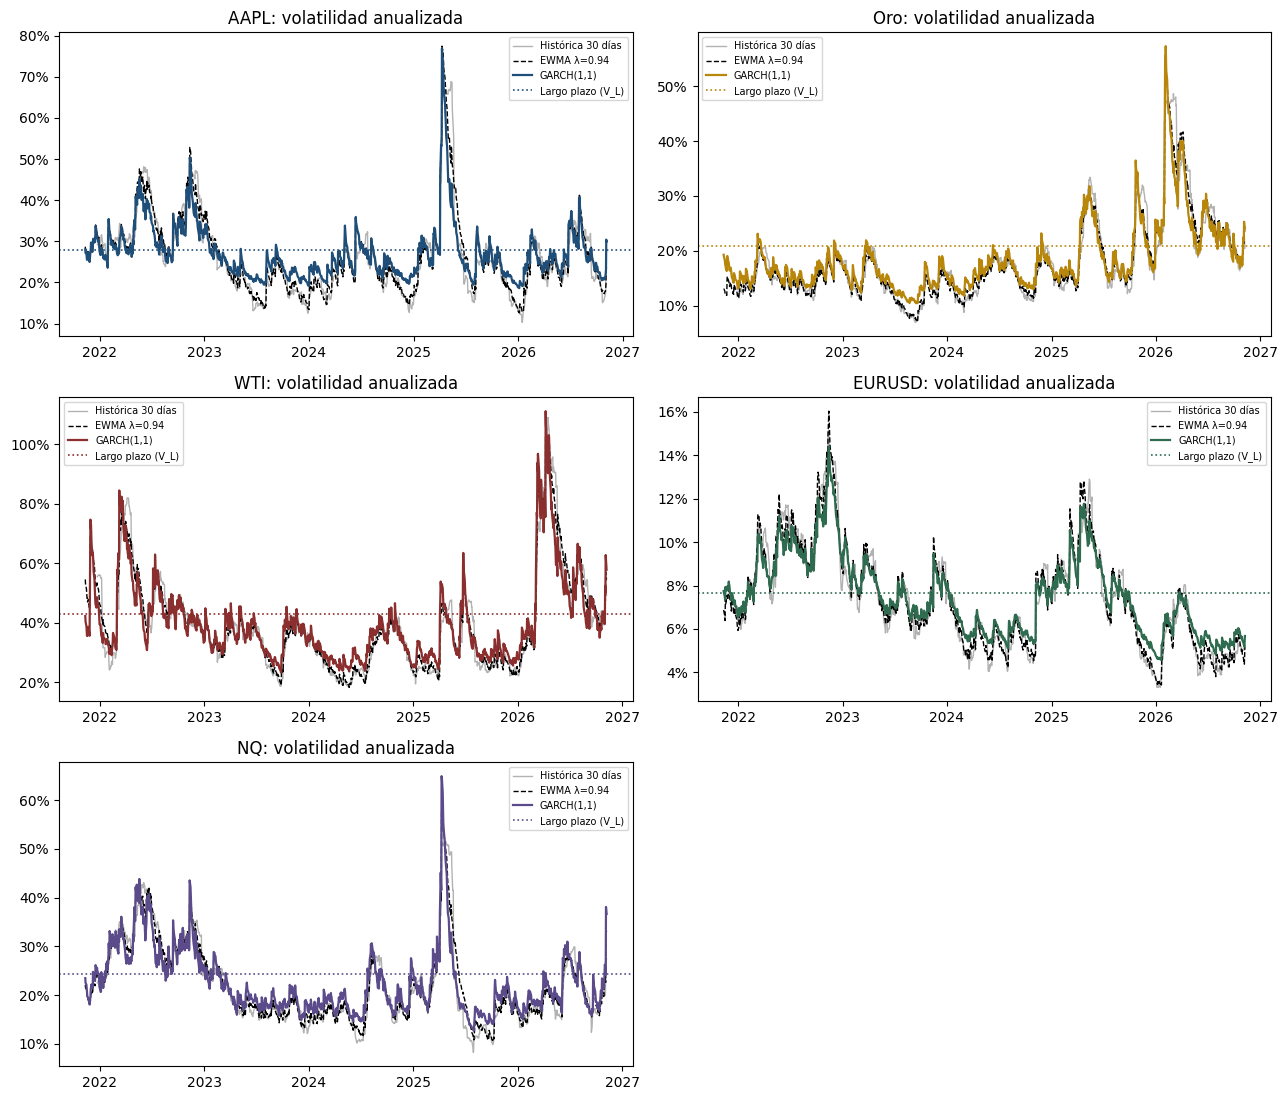

Lectura: GARCH sube rápido tras un shock y regresa a su nivel de largo plazo (línea punteada).


In [7]:
fig, axs = plt.subplots((len(NOMBRES) + 1) // 2, 2, figsize=(13, 3.7 * ((len(NOMBRES) + 1) // 2)))
for ax, t in zip(axs.ravel(), NOMBRES):
    idx = REND[t].index
    ax.plot(idx, VOL30[t], color="gray", alpha=0.6, lw=1, label="Histórica 30 días")
    ax.plot(idx, vol_anual_desde_var(var_ewma(M[t]["u"])), color="black", lw=1, ls="--", label="EWMA λ=0.94")
    ax.plot(idx, vol_anual_desde_var(M[t]["v"]), color=COLORES[t], lw=1.6, label="GARCH(1,1)")
    ax.axhline(vol_anual_desde_var(M[t]["VL"]), color=COLORES[t], ls=":", lw=1.2, label="Largo plazo (V_L)")
    ax.set_title(f"{t}: volatilidad anualizada")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
    ax.legend(fontsize=7)
for ax in axs.ravel()[len(NOMBRES):]:
    ax.axis("off")
mostrar("01_volatilidades")
print("Lectura: GARCH sube rápido tras un shock y regresa a su nivel de largo plazo (línea punteada).")

## 5. ¿Qué modelo elegir? (Hull 23.4 y 23.5)
Log-verosimilitud (más alta es mejor), AIC/BIC (más bajo es mejor) y prueba de Ljung-Box: si los residuos
$u^2/\sigma^2$ ya no tienen autocorrelación (p > 0.05), el modelo capturó el *clustering* de volatilidad.

In [8]:
from statsmodels.stats.diagnostic import acorr_ljungbox

def lb_pvalue(serie, lags=10):
    return float(acorr_ljungbox(serie, lags=[lags], return_df=True)["lb_pvalue"].iloc[0])

filas = []
for t in NOMBRES:
    u, n = M[t]["u"], len(M[t]["u"])
    grid = np.arange(0.80, 0.995, 0.005)
    lls = [loglik(var_ewma(u, l), u) for l in grid]
    lam_opt = float(grid[int(np.argmax(lls))])
    M[t]["lam_opt"] = lam_opt
    modelos = {"Volatilidad constante": (np.full(n, np.var(u)), 1),
               "EWMA λ=0.94": (var_ewma(u, 0.94), 0),
               f"EWMA λ óptimo ({lam_opt:.3f})": (var_ewma(u, lam_opt), 1),
               "GARCH(1,1)": (M[t]["v"], 3)}
    for nombre, (v, k) in modelos.items():
        ll = loglik(v, u)
        filas.append({"Activo": t, "Modelo": nombre, "Log-verosim.": ll, "AIC": 2 * k - 2 * ll,
                      "BIC": k * np.log(n) - 2 * ll, "p Ljung-Box (u²/σ²)": lb_pvalue(u ** 2 / v)})
comparacion = pd.DataFrame(filas)
print(comparacion.round(3).to_string(index=False))
LB_CRUDO = {t: lb_pvalue(M[t]["u"] ** 2) for t in NOMBRES}
print("\nu² sin modelar (hay clustering si p es pequeño):", {t: round(v, 4) for t, v in LB_CRUDO.items()})
mejor = comparacion.loc[comparacion.groupby("Activo")["AIC"].idxmin(), ["Activo", "Modelo"]]
print("Modelo con menor AIC por activo:\n", mejor.to_string(index=False))

Activo                Modelo  Log-verosim.      AIC      BIC  p Ljung-Box (u²/σ²)
  AAPL Volatilidad constante     -2490.438 4982.875 4988.008                0.000
  AAPL           EWMA λ=0.94     -2444.068 4888.136 4888.136                0.286
  AAPL EWMA λ óptimo (0.960)     -2440.603 4883.207 4888.339                0.036
  AAPL            GARCH(1,1)     -2420.918 4847.835 4863.233                0.100
   Oro Volatilidad constante     -2029.363 4060.726 4065.862                0.000
   Oro           EWMA λ=0.94     -1929.290 3858.580 3858.580                0.570
   Oro EWMA λ óptimo (0.950)     -1928.673 3859.347 3864.482                0.389
   Oro            GARCH(1,1)     -1919.399 3844.798 3860.205                0.456
   WTI Volatilidad constante     -3006.905 6015.809 6020.944                0.000
   WTI           EWMA λ=0.94     -2894.395 5788.791 5788.791                0.124
   WTI EWMA λ óptimo (0.935)     -2894.227 5790.454 5795.589                0.272
   WTI          

## 6. Pronóstico de volatilidad con GARCH(1,1) (Hull 23.6)
$$E[\sigma^2_{n+k}]=V_L+(\alpha+\beta)^k(\sigma^2_{n}-V_L)$$
Para valuar una opción que vence en $T$ días se usa la **volatilidad promedio** de esos días. Esa es la que entra al árbol.

Volatilidad anual promedio esperada (estructura temporal GARCH):
           AAPL    Oro    WTI EURUSD     NQ
10 días   28.9%  23.4%  54.0%   5.7%  34.0%
21 días   28.7%  23.2%  53.0%   5.8%  33.1%
63 días   28.4%  22.7%  50.2%   6.2%  30.5%
126 días  28.2%  22.2%  47.7%   6.5%  28.3%
252 días  28.1%  21.6%  45.6%   6.9%  26.5%

Control con la fórmula continua de Hull (126 días): {'AAPL': '28.20%', 'Oro': '22.17%', 'WTI': '47.70%', 'EURUSD': '6.52%', 'NQ': '28.30%'}


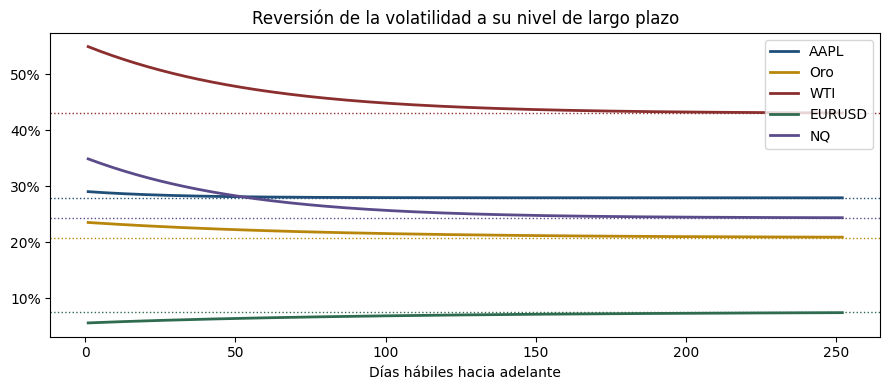

In [9]:
def pron_var(params, u, v, H):
    omega, alpha, beta = params
    VL = omega / (1 - alpha - beta)
    v_next = omega + alpha * u[-1] ** 2 + beta * v[-1]
    k = np.arange(H)
    return VL + (alpha + beta) ** k * (v_next - VL)


def vol_promedio(t, dias):
    fv = pron_var(M[t]["p"], M[t]["u"], M[t]["v"], max(int(round(dias)), 1))
    return float(np.sqrt(252 * fv.mean()) / 100)


def vol_promedio_hull(t, dias):
    # Fórmula continua de Hull: V_L + (1-e^{-aT})/(aT) (V(0)-V_L), a = ln(1/(α+β))
    omega, alpha, beta = M[t]["p"]
    a = np.log(1 / (alpha + beta))
    return float(np.sqrt(252 * (M[t]["VL"] + (1 - np.exp(-a * dias)) / (a * dias) * (M[t]["v_next"] - M[t]["VL"]))) / 100)


plazos = [10, 21, 63, 126, 252]
estructura = pd.DataFrame({t: [vol_promedio(t, d) for d in plazos] for t in NOMBRES},
                          index=[f"{d} días" for d in plazos])
print("Volatilidad anual promedio esperada (estructura temporal GARCH):")
print(estructura.map("{:.1%}".format))
print("\nControl con la fórmula continua de Hull (126 días):", {t: f"{vol_promedio_hull(t, 126):.2%}" for t in NOMBRES})

fig, ax = plt.subplots(figsize=(9, 4))
dd = np.arange(1, 253)
for t in NOMBRES:
    fv = pron_var(M[t]["p"], M[t]["u"], M[t]["v"], 252)
    ax.plot(dd, vol_anual_desde_var(fv), color=COLORES[t], lw=2, label=t)
    ax.axhline(vol_anual_desde_var(M[t]["VL"]), color=COLORES[t], ls=":", lw=1)
ax.set_xlabel("Días hábiles hacia adelante"); ax.set_title("Reversión de la volatilidad a su nivel de largo plazo")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}")); ax.legend()
mostrar("02_estructura_temporal")

## 7. Correlaciones y VaR del portafolio (Hull 23.7 y 23.8)
Con EWMA: $\text{cov}_n=\lambda\,\text{cov}_{n-1}+(1-\lambda)x_{n-1}y_{n-1}$ y $\rho_n=\text{cov}_n/(\sigma_x\sigma_y)$.
El portafolio de USD 1 millón usa los pesos de **mínima varianza** (como en la primera práctica), y su VaR combina la
volatilidad de GARCH de cada activo con la correlación EWMA actual.

Correlación EWMA actual:
         AAPL   Oro   WTI  EURUSD    NQ
AAPL    1.00  0.32 -0.36    0.08  0.25
Oro     0.32  1.00 -0.55    0.35  0.20
WTI    -0.36 -0.55  1.00   -0.17 -0.32
EURUSD  0.08  0.35 -0.17    1.00 -0.05
NQ      0.25  0.20 -0.32   -0.05  1.00

Correlación muestral (todo el periodo):
         AAPL   Oro   WTI  EURUSD    NQ
AAPL    1.00  0.02  0.00    0.15  0.68
Oro     0.02  1.00  0.04    0.34  0.11
WTI     0.00  0.04  1.00   -0.05 -0.00
EURUSD  0.15  0.34 -0.05    1.00  0.20
NQ      0.68  0.11 -0.00    0.20  1.00

Pesos de mínima varianza: {'AAPL': '28.4%', 'Oro': '59.9%', 'WTI': '11.8%'}
VaR 95%: 1 día USD 16,211   10 días USD 51,264
VaR 99%: 1 día USD 22,928   10 días USD 72,503
Beneficio de diversificación: el VaR del portafolio es 45.7% menor que la suma de los VaR individuales.

Cobertura de AAPL con NQ: ρ = 0.25, h* = 0.20, contratos = 0.11 (venta de 0); cada contrato vale USD 539,170. Con Micro E-mini (MNQ, USD 2 por punto) serían 1.1 contratos (venta de 1). Efe

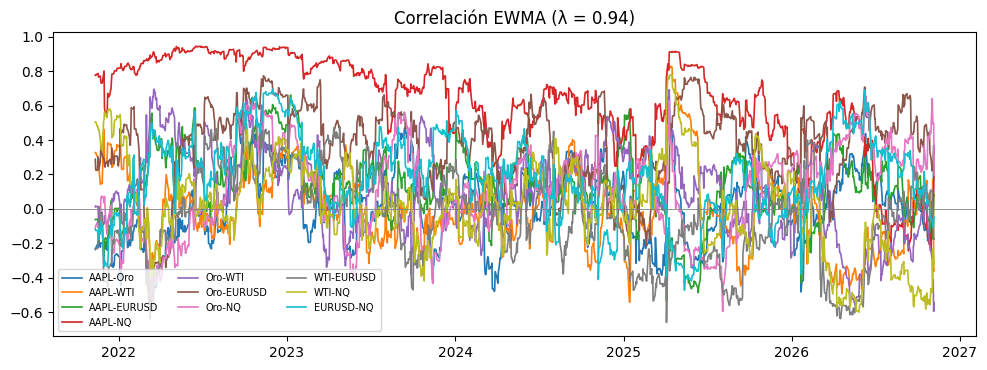

In [10]:
def ewma_cov_series(x, y, lam=LAMBDA_EWMA):
    cov = np.empty(len(x)); cov[0] = np.mean(x[:30] * y[:30])
    for i in range(1, len(x)):
        cov[i] = lam * cov[i - 1] + (1 - lam) * x[i - 1] * y[i - 1]
    return cov

X = rend_comun[NOMBRES]
CORR_SERIES, CORR_HOY = {}, pd.DataFrame(np.eye(len(NOMBRES)), index=NOMBRES, columns=NOMBRES)
var_ew = {t: var_ewma(X[t].values) for t in NOMBRES}
for i, a in enumerate(NOMBRES):
    for b in NOMBRES[i + 1:]:
        c = ewma_cov_series(X[a].values, X[b].values) / np.sqrt(var_ew[a] * var_ew[b])
        CORR_SERIES[f"{a}-{b}"] = pd.Series(c, index=X.index)
        CORR_HOY.loc[a, b] = CORR_HOY.loc[b, a] = float(c[-1])
print("Correlación EWMA actual:\n", CORR_HOY.round(2))
print("\nCorrelación muestral (todo el periodo):\n", X.corr().round(2))

# Pesos de mínima varianza (sin ventas en corto) con la covarianza muestral anualizada
cov_anual = (X[PORTAFOLIO] / 100).cov() * 252
k = len(PORTAFOLIO)
res = minimize(lambda w: w @ cov_anual.values @ w, np.full(k, 1 / k), method="SLSQP",
               bounds=[(0, 1)] * k, constraints=({"type": "eq", "fun": lambda w: w.sum() - 1},))
PESOS = pd.Series(res.x, index=PORTAFOLIO)
MONTOS = PESOS * INVERSION

# VaR paramétrico a 1 y 10 días con σ GARCH de mañana y correlación EWMA de hoy
sig_d = np.array([np.sqrt(M[t]["v_next"]) / 100 for t in PORTAFOLIO])
Cp = CORR_HOY.loc[PORTAFOLIO, PORTAFOLIO].values
sd_port_1d = float(np.sqrt((MONTOS.values * sig_d) @ Cp @ (MONTOS.values * sig_d)))
sd_indiv = MONTOS.values * sig_d
VAR_PORT = {nivel: {"1 día": norm.ppf(nivel) * sd_port_1d, "10 días": norm.ppf(nivel) * sd_port_1d * np.sqrt(10)}
            for nivel in (0.95, 0.99)}
beneficio_div = 1 - sd_port_1d / sd_indiv.sum()
print("\nPesos de mínima varianza:", PESOS.map("{:.1%}".format).to_dict())
for nivel, d in VAR_PORT.items():
    print(f"VaR {nivel:.0%}: 1 día USD {d['1 día']:,.0f}   10 días USD {d['10 días']:,.0f}")
print(f"Beneficio de diversificación: el VaR del portafolio es {beneficio_div:.1%} menor que la suma de los VaR individuales.")

# Cobertura de varianza mínima con futuros E-mini Nasdaq-100 (Hull 3.4): h* = ρ σ_S / σ_F, N* = h* V_A / (F · multiplicador)
COBERTURA = None
if "NQ" in NOMBRES and COBERTURA_NQ in MONTOS:
    sig_s = np.sqrt(M[COBERTURA_NQ]["v_next"]); sig_f = np.sqrt(M["NQ"]["v_next"])
    rho = float(CORR_HOY.loc[COBERTURA_NQ, "NQ"])
    h = rho * sig_s / sig_f
    valor_fut = S0["NQ"] * MULT_NQ
    N_opt = h * MONTOS[COBERTURA_NQ] / valor_fut
    var_sin = np.sqrt(M[COBERTURA_NQ]["v_next"]) / 100 * MONTOS[COBERTURA_NQ]
    N_micro = N_opt * MULT_NQ / 2               # Micro E-mini (MNQ): USD 2 por punto
    COBERTURA = dict(activo=COBERTURA_NQ, rho=rho, h=h, contratos=N_opt, contratos_redondeo=int(round(N_opt)),
                     contratos_micro=N_micro, contratos_micro_redondeo=int(round(N_micro)),
                     valor_contrato=valor_fut, efectividad=rho ** 2,
                     sd_sin=float(var_sin), sd_con=float(var_sin * np.sqrt(max(1 - rho ** 2, 0))))
    print(f"\nCobertura de {COBERTURA_NQ} con NQ: ρ = {rho:.2f}, h* = {h:.2f}, contratos = {N_opt:.2f} "
          f"(venta de {int(round(N_opt))}); cada contrato vale USD {valor_fut:,.0f}. "
          f"Con Micro E-mini (MNQ, USD 2 por punto) serían {N_micro:.1f} contratos (venta de {int(round(N_micro))}). "
          f"Efectividad ρ² = {rho ** 2:.0%}: la desviación diaria de la posición baja de USD {COBERTURA['sd_sin']:,.0f} "
          f"a USD {COBERTURA['sd_con']:,.0f}.")

fig, ax = plt.subplots(figsize=(10, 3.8))
for nombre, s in CORR_SERIES.items():
    ax.plot(s.index, s, lw=1.2, label=nombre)
ax.axhline(0, color="gray", lw=0.6); ax.set_title("Correlación EWMA (λ = 0.94)"); ax.legend(fontsize=7, ncol=3)
mostrar("03_correlaciones")

## 8. Monte Carlo con GARCH y choques correlacionados (Hull 22.6)
Cada día $u_t=\sigma_t z_t$ y la varianza se actualiza con GARCH. Los choques $z$ de todos los activos se
correlacionan con la matriz EWMA actual (Cholesky).
- Para **pronosticar precios** se usa el rendimiento esperado supuesto `MU_ANUAL`.
- Para **valuar opciones** se usa la deriva neutral al riesgo: $r-q$ en la acción y cero en los futuros (Duan, 1995).

                     AAPL        Oro       WTI  EURUSD          NQ
Precio hoy       342.3700  4116.3999   90.4400  1.1171  26958.5000
P5               254.1741  3256.9631   48.2214  1.0356  19928.3043
P25              308.6897  3784.5783   68.7256  1.0851  24265.2889
Mediana          351.1088  4194.9176   84.7840  1.1161  27539.8794
P75              400.5794  4615.1513  104.1020  1.1514  31290.6086
P95              483.9548  5382.9235  143.3436  1.2057  37954.8349
Prob. sube         0.5548     0.5474    0.4182  0.4918      0.5418
VaR 99% 10 días    0.1246     0.1037    0.2355  0.0268      0.1516

Portafolio, VaR a 10 días por Monte Carlo GARCH: 95% USD 47,636 · 99% USD 67,091 · Expected shortfall 99% USD 77,511


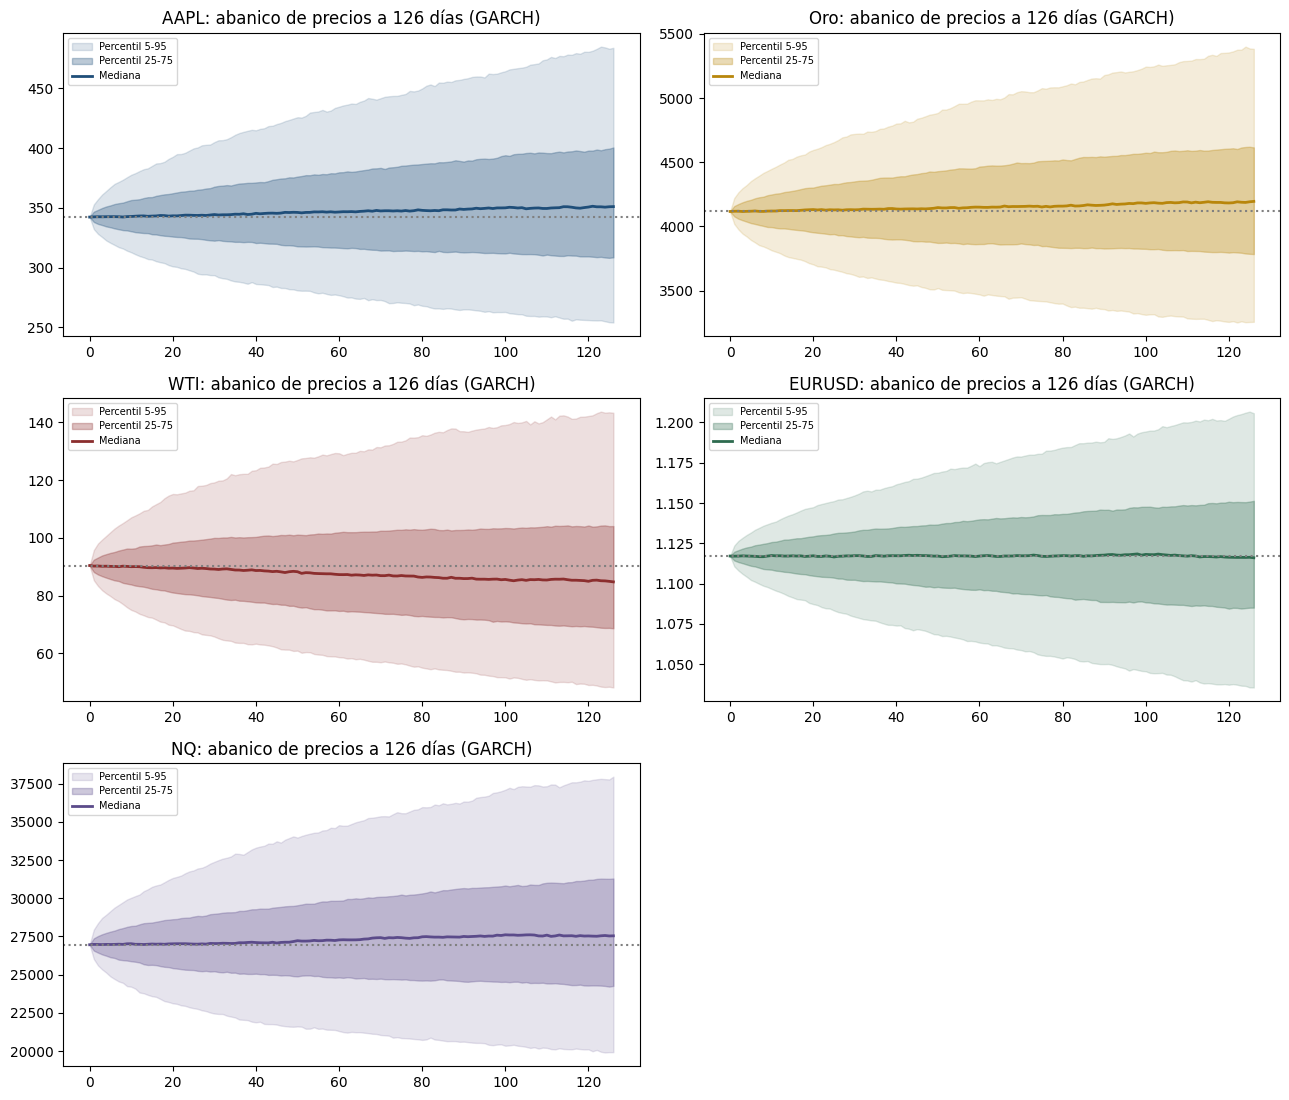

In [11]:
L_CHOL = np.linalg.cholesky(CORR_HOY.values + 1e-10 * np.eye(len(NOMBRES)))

def simular_conjunto(H, n_sim, derivas, rng, nombres=NOMBRES):
    # Trayectorias GARCH correlacionadas; derivas: dict activo -> deriva anual. Regresa dict activo -> matriz (H+1, n_sim)
    idx = [NOMBRES.index(t) for t in nombres]
    L = np.linalg.cholesky(CORR_HOY.values[np.ix_(idx, idx)] + 1e-10 * np.eye(len(idx)))
    v = {t: np.full(n_sim, M[t]["p"][0] + M[t]["p"][1] * M[t]["u"][-1] ** 2 + M[t]["p"][2] * M[t]["v"][-1]) for t in nombres}
    S = {t: np.empty((H + 1, n_sim)) for t in nombres}
    for t in nombres:
        S[t][0] = S0[t]
    for k in range(1, H + 1):
        Z = rng.standard_normal((n_sim, len(nombres))) @ L.T
        for j, t in enumerate(nombres):
            omega, alpha, beta = M[t]["p"]
            sig = np.sqrt(v[t])
            ret = derivas[t] / 252 - 0.5 * (sig / 100) ** 2 + (sig / 100) * Z[:, j]
            S[t][k] = S[t][k - 1] * np.exp(ret)
            v[t] = omega + alpha * (sig * Z[:, j]) ** 2 + beta * v[t]
    return S


def deriva_neutral(t):
    return 0.0 if ES_FUTURO[t] else R_FREE - DIV_YIELD.get(t, 0.0)


rng = np.random.default_rng(SEED)
SIM = simular_conjunto(HORIZON_DAYS, N_SIM, MU_ANUAL, rng)

resumen_mc = {}
for t in NOMBRES:
    ST = SIM[t][-1]
    q5, q25, q50, q75, q95 = np.percentile(ST, [5, 25, 50, 75, 95])
    r10 = SIM[t][10] / S0[t] - 1
    resumen_mc[t] = {"Precio hoy": S0[t], "P5": q5, "P25": q25, "Mediana": q50, "P75": q75, "P95": q95,
                     "Prob. sube": float((ST > S0[t]).mean()), "VaR 99% 10 días": float(-np.percentile(r10, 1))}
print(pd.DataFrame(resumen_mc).round(4))

# Portafolio de USD 1 millón con las mismas trayectorias
uds = {t: MONTOS[t] / S0[t] for t in PORTAFOLIO}
V_port = sum(SIM[t] * uds[t] for t in PORTAFOLIO)
pnl10 = V_port[10] - INVERSION
VAR_MC = {"95%": float(-np.percentile(pnl10, 5)), "99%": float(-np.percentile(pnl10, 1)),
          "ES 99%": float(-pnl10[pnl10 <= np.percentile(pnl10, 1)].mean())}
print(f"\nPortafolio, VaR a 10 días por Monte Carlo GARCH: 95% USD {VAR_MC['95%']:,.0f} · 99% USD {VAR_MC['99%']:,.0f} · "
      f"Expected shortfall 99% USD {VAR_MC['ES 99%']:,.0f}")

fig, axs = plt.subplots((len(NOMBRES) + 1) // 2, 2, figsize=(13, 3.7 * ((len(NOMBRES) + 1) // 2)))
for ax, t in zip(axs.ravel(), NOMBRES):
    dias = np.arange(HORIZON_DAYS + 1)
    p = np.percentile(SIM[t], [5, 25, 50, 75, 95], axis=1)
    ax.fill_between(dias, p[0], p[4], color=COLORES[t], alpha=0.15, label="Percentil 5-95")
    ax.fill_between(dias, p[1], p[3], color=COLORES[t], alpha=0.30, label="Percentil 25-75")
    ax.plot(dias, p[2], color=COLORES[t], lw=2, label="Mediana")
    ax.axhline(S0[t], color="gray", ls=":")
    ax.set_title(f"{t}: abanico de precios a {HORIZON_DAYS} días (GARCH)"); ax.legend(fontsize=7)
for ax in axs.ravel()[len(NOMBRES):]:
    ax.axis("off")
mostrar("04_abanico_precios")

## 9. Back testing del VaR (Hull 22.8)
VaR de 1 día con la volatilidad de cada modelo y conteo de **excepciones**. La **prueba de Kupiec** indica si el número
observado es compatible con lo esperado (p > 0.05: el modelo pasa). GARCH se reestima cada 63 días sin mirar el futuro.

Activo Confianza         Modelo  Días  Excepciones  Tasa observada  Tasa esperada  p Kupiec
  AAPL       95%     GARCH(1,1)   501           23          0.0459           0.05    0.6702
  AAPL       95%           EWMA   501           25          0.0499           0.05    0.9918
  AAPL       95% Histórica 250d   501           25          0.0499           0.05    0.9918
  AAPL       99%     GARCH(1,1)   501           10          0.0200           0.01    0.0485
  AAPL       99%           EWMA   501           12          0.0240           0.01    0.0078
  AAPL       99% Histórica 250d   501           10          0.0200           0.01    0.0485
   Oro       95%     GARCH(1,1)   503           33          0.0656           0.05    0.1246
   Oro       95%           EWMA   503           28          0.0557           0.05    0.5666
   Oro       95% Histórica 250d   503           32          0.0636           0.05    0.1779
   Oro       99%     GARCH(1,1)   503           15          0.0298           0.0

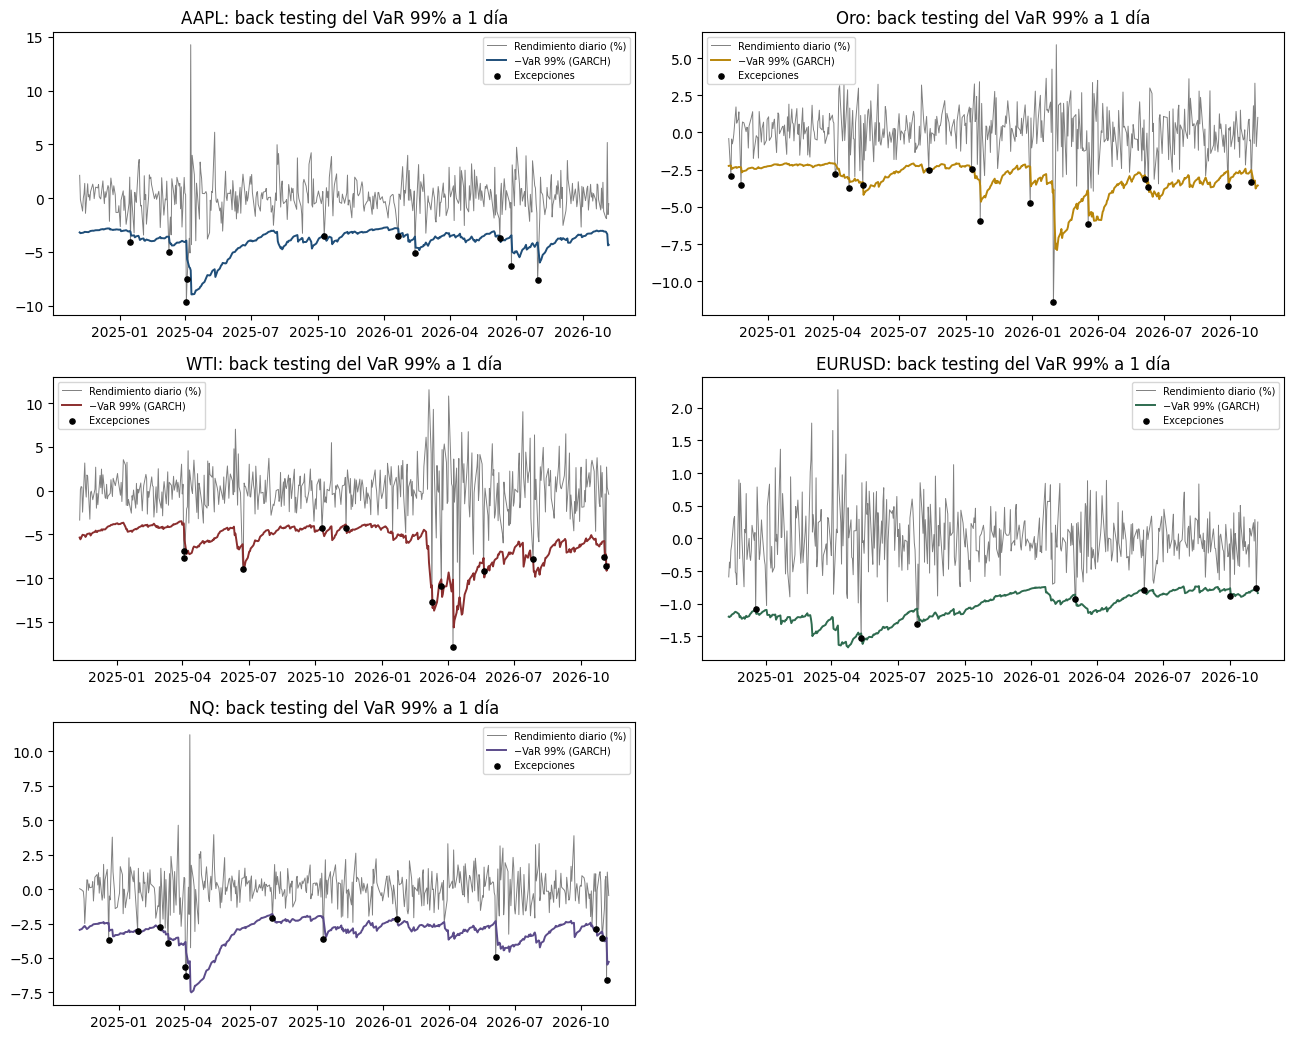

In [12]:
def kupiec(x, N, p):
    if x == 0:
        lr = -2 * N * np.log(1 - p)
    else:
        ph = x / N
        lr = -2 * ((N - x) * np.log((1 - p) / (1 - ph)) + x * np.log(p / ph))
    return float(1 - chi2.cdf(lr, 1))


def varianzas_backtest(t, inicio, refit=63):
    u = M[t]["u"]; n = len(u)
    vg = np.full(n, np.nan)
    for s in range(inicio, n, refit):
        fin = min(n, s + refit)
        p = ajustar_garch(u[:s])
        vg[s:fin] = var_garch(p, u[:fin], v0=np.var(u[:s]))[s:fin]
    vh = np.full(n, np.nan)
    for s in range(inicio, n):
        vh[s] = np.var(u[s - 250:s])
    return {"GARCH(1,1)": vg, "EWMA": var_ewma(u), "Histórica 250d": vh}


filas_bt, BT = [], {}
for t in NOMBRES:
    u = M[t]["u"]; inicio = int(len(u) * 0.6)
    vp = varianzas_backtest(t, inicio)
    BT[t] = dict(inicio=inicio, var=vp)
    for nivel in (0.95, 0.99):
        z = norm.ppf(nivel)
        for nombre, v in vp.items():
            exc = u[inicio:] < -z * np.sqrt(v[inicio:])
            N, x = len(exc), int(exc.sum())
            filas_bt.append({"Activo": t, "Confianza": f"{nivel:.0%}", "Modelo": nombre, "Días": N, "Excepciones": x,
                             "Tasa observada": x / N, "Tasa esperada": 1 - nivel, "p Kupiec": kupiec(x, N, 1 - nivel)})
bt = pd.DataFrame(filas_bt)
print(bt.round(4).to_string(index=False))

fig, axs = plt.subplots((len(NOMBRES) + 1) // 2, 2, figsize=(13, 3.5 * ((len(NOMBRES) + 1) // 2)))
z99 = norm.ppf(0.99)
for ax, t in zip(axs.ravel(), NOMBRES):
    u, ini, vg = M[t]["u"], BT[t]["inicio"], BT[t]["var"]["GARCH(1,1)"]
    idx = REND[t].index[ini:]
    lim = -z99 * np.sqrt(vg[ini:])
    ax.plot(idx, u[ini:], color="gray", lw=0.7, label="Rendimiento diario (%)")
    ax.plot(idx, lim, color=COLORES[t], lw=1.4, label="−VaR 99% (GARCH)")
    exc = u[ini:] < lim
    ax.scatter(idx[exc], u[ini:][exc], color="black", s=14, zorder=3, label="Excepciones")
    ax.set_title(f"{t}: back testing del VaR 99% a 1 día"); ax.legend(fontsize=7)
for ax in axs.ravel()[len(NOMBRES):]:
    ax.axis("off")
mostrar("05_backtesting")

## 10. Las opciones del proyecto con árbol CRR y volatilidad de GARCH (Hull cap. 13 y 18)
El árbol necesita **una** volatilidad; GARCH da la **volatilidad promedio esperada** durante la vida de cada opción.
En las opciones sobre futuros (oro, WTI y Euro FX) la probabilidad neutral al riesgo usa crecimiento 1, lo que equivale a
poner $q = r$. Cada pata se valúa con la volatilidad histórica, la de GARCH y la implícita del mercado.

In [13]:
def crr(S0_, K, r, sigma, T, N=N_ARBOL, tipo="put", americana=True, q=0.0):
    dt = T / N
    u_ = np.exp(sigma * np.sqrt(dt)); d_ = 1 / u_
    p = (np.exp((r - q) * dt) - d_) / (u_ - d_); disc = np.exp(-r * dt)
    sg = 1 if tipo == "call" else -1
    niveles = [None] * 3
    j = np.arange(N + 1)
    V = np.maximum(sg * (S0_ * u_ ** (N - j) * d_ ** j - K), 0.0)
    for i in range(N - 1, -1, -1):
        k = np.arange(i + 1)
        cont = disc * (p * V[:i + 1] + (1 - p) * V[1:i + 2])
        V = np.maximum(cont, np.maximum(sg * (S0_ * u_ ** (i - k) * d_ ** k - K), 0.0)) if americana else cont
        if i <= 2:
            niveles[i] = V
    return V[0], niveles, u_, d_, dt


def griegas(S0_, K, r, sigma, T, N=N_ARBOL, tipo="put", americana=True, q=0.0):
    precio, niv, u_, d_, dt = crr(S0_, K, r, sigma, T, N, tipo, americana, q)
    f0, f1, f2 = niv[0][0], niv[1], niv[2]
    delta = (f1[0] - f1[1]) / (S0_ * u_ - S0_ * d_)
    gamma = ((f2[0] - f2[1]) / (S0_ * u_ ** 2 - S0_) - (f2[1] - f2[2]) / (S0_ - S0_ * d_ ** 2)) / (0.5 * (S0_ * u_ ** 2 - S0_ * d_ ** 2))
    theta = (f2[1] - f0) / (2 * dt) / 365
    vega = crr(S0_, K, r, sigma + 0.01, T, N, tipo, americana, q)[0] - precio
    return dict(precio=precio, delta=delta, gamma=gamma, theta=theta, vega=vega)


def q_de(t):
    return R_FREE if ES_FUTURO[t] else DIV_YIELD.get(t, 0.0)


def vol_implicita(precio, S, K, T, tipo, q):
    # Volatilidad que iguala el árbol americano (200 pasos) con la prima observada
    f = lambda s: crr(S, K, R_FREE, s, T, 200, tipo, True, q)[0] - precio
    try:
        return brentq(f, 0.01, 3.0)
    except ValueError:
        return np.nan


patas = pd.DataFrame(POSICIONES)
for c in ("S_captura", "fecha_captura", "prima_mercado"):
    if c not in patas:
        patas[c] = np.nan
patas["venc"] = pd.to_datetime(patas["venc"])
patas["dias_nat"] = (patas["venc"] - FECHA_VAL).dt.days
patas["dias_hab"] = [int(np.busday_count(FECHA_VAL.date(), d.date())) for d in patas["venc"]]
patas = patas[patas["dias_nat"] > 0].reset_index(drop=True)
patas["T"] = patas["dias_nat"] / 365
patas["S"] = patas["activo"].map(S0)
patas["q"] = patas["activo"].map(q_de)
patas["iv_origen"] = np.where(patas["iv"].notna(), "captura",
                              np.where(patas["prima_mercado"].notna(), "despejada del settle", "despejada de la prima"))
for i, f in patas.iterrows():
    if pd.isna(f["iv"]):
        # Con el precio y la fecha de la captura; si no se dieron, con los de hoy
        S_c = f["S"] if pd.isna(f["S_captura"]) else f["S_captura"]
        T_c = f["T"] if pd.isna(f["fecha_captura"]) else (f["venc"] - pd.Timestamp(f["fecha_captura"])).days / 365
        prima_iv = f["prima"] if pd.isna(f["prima_mercado"]) else f["prima_mercado"]
        patas.loc[i, "iv"] = vol_implicita(prima_iv, S_c, f["K"], T_c, f["tipo"], f["q"])
    if pd.isna(f["prima"]):
        patas.loc[i, "prima"] = crr(f["S"], f["K"], R_FREE, patas.loc[i, "iv"], f["T"], N_ARBOL, f["tipo"], True, f["q"])[0]
patas["vol_hist"] = patas["activo"].map(VOL_HIST_1A)
patas["vol_garch"] = [vol_promedio(a, d) for a, d in zip(patas["activo"], patas["dias_hab"])]

filas = []
for _, f in patas.iterrows():
    fila = {"Estrategia": f["estrategia"], "Pata": f"{'+' if f['pos'] > 0 else '−'}{f['tipo']} {f['K']:g}",
            "Días": f["dias_nat"], "Prima captura": f["prima"],
            "Prima mercado": f["prima"] if pd.isna(f["prima_mercado"]) else f["prima_mercado"]}
    for etiqueta, col in [("hist", "vol_hist"), ("GARCH", "vol_garch"), ("IV", "iv")]:
        fila[f"σ {etiqueta}"] = f[col]
        fila[f"Árbol σ {etiqueta}"] = crr(f["S"], f["K"], R_FREE, f[col], f["T"], N_ARBOL, f["tipo"], True, f["q"])[0]
    g = griegas(f["S"], f["K"], R_FREE, f["vol_garch"], f["T"], N_ARBOL, f["tipo"], True, f["q"])
    fila.update({"Δ (σ GARCH)": g["delta"], "Γ": g["gamma"], "Vega/pto": g["vega"], "Θ/día": g["theta"]})
    filas.append(fila)
tabla_patas = pd.DataFrame(filas)
pd.set_option("display.width", 200)
print(tabla_patas.round(4).to_string(index=False))
print("\nNota: la prima de la captura es de la fecha de la captura; si el subyacente se movió desde entonces, se compara\n"
      "contra el árbol con σ IV (precio de mercado estimado hoy). Actualicen la IV de cada pata con la cadena del día.")

             Estrategia        Pata  Días  Prima captura  Prima mercado  σ hist  Árbol σ hist  σ GARCH  Árbol σ GARCH   σ IV  Árbol σ IV  Δ (σ GARCH)       Γ  Vega/pto   Θ/día
          AAPL Call 345   +call 345    40        13.5000        13.5000  0.2485       10.6781   0.2865        12.3990 0.2717     11.7258       0.5046  0.0123    0.4533 -0.1792
 AAPL Bull Call 345/355   +call 345    40        13.5000        13.5000  0.2485       10.6781   0.2865        12.3990 0.2717     11.7258       0.5046  0.0123    0.4533 -0.1792
 AAPL Bull Call 345/355   −call 355    40         7.1487         7.1487  0.2485        6.7047   0.2865         8.3449 0.2588      7.1487       0.3861  0.0118    0.4301 -0.1686
Oro Bull Call 4190/4400  +call 4190    16        98.3040        46.0000  0.2831       65.6965   0.2338        49.4550 0.2026     39.4945       0.3672  0.0019    3.2698 -2.3677
Oro Bull Call 4190/4400  −call 4400    16        33.7340        12.2000  0.2831       16.4927   0.2338         8.2993 0.

## 10b. ¿Conviene ejercer antes? (opción americana contra europea)
- **Prima de ejercicio anticipado** = precio americano − precio europeo.
- **Precio crítico de la put**: si el subyacente cae debajo de él, lo óptimo es ejercer hoy.
- En una call sobre una acción **sin dividendos** nunca conviene ejercer antes. En opciones sobre futuros sí puede convenir
  cuando están muy dentro del dinero, porque ejercer libera el valor intrínseco y permite invertirlo.

In [14]:
filas, CRITICO = [], {}
for _, f in patas.drop_duplicates(["activo", "tipo", "K", "venc"]).iterrows():
    am = crr(f["S"], f["K"], R_FREE, f["vol_garch"], f["T"], N_ARBOL, f["tipo"], True, f["q"])[0]
    eu = crr(f["S"], f["K"], R_FREE, f["vol_garch"], f["T"], N_ARBOL, f["tipo"], False, f["q"])[0]
    crit = None
    if f["tipo"] == "put":
        grid = np.linspace(0.4 * f["K"], f["K"], 80)
        ej = [crr(s, f["K"], R_FREE, f["vol_garch"], f["T"], 300, "put", True, f["q"])[0] - (f["K"] - s) < 1e-7 for s in grid]
        crit = float(grid[np.where(ej)[0].max()]) if any(ej) else None
    CRITICO[f"{f['activo']} {f['tipo']} {f['K']:g}"] = crit
    filas.append({"Opción": f"{f['activo']} {f['tipo']} {f['K']:g}", "σ GARCH": f["vol_garch"], "Americana": am,
                  "Europea": eu, "Prima de ejercicio anticipado": am - eu,
                  "% del precio": 100 * (am - eu) / eu if eu > 0 else np.nan, "Precio crítico (put)": crit})
tabla_amer = pd.DataFrame(filas)
print(tabla_amer.round(4).to_string(index=False))
print("\nLectura: el árbol americano solo agrega valor relevante en las puts dentro del dinero y en opciones sobre futuros con plazo largo.")

           Opción  σ GARCH  Americana  Europea  Prima de ejercicio anticipado  % del precio  Precio crítico (put)
    AAPL call 345   0.2865    12.3990  12.3990                         0.0000        0.0000                   NaN
    AAPL call 355   0.2865     8.3449   8.3449                         0.0000        0.0000                   NaN
    Oro call 4190   0.2338    49.4550  49.4463                         0.0087        0.0176                   NaN
    Oro call 4400   0.2338     8.2993   8.2985                         0.0008        0.0095                   NaN
     WTI put 91.5   0.5439     3.6561   3.6556                         0.0005        0.0128               70.6519
       WTI put 85   0.5439     1.0213   1.0212                         0.0001        0.0074               65.6329
EURUSD call 1.115   0.0582     0.0080   0.0080                         0.0000        0.0419                   NaN
 EURUSD put 1.115   0.0582     0.0059   0.0059                         0.0000        0.0

## 11. Comprobación: Monte Carlo GARCH (Duan) contra el árbol, opciones europeas
Si el árbol con la volatilidad promedio de GARCH se parece al Monte Carlo con la volatilidad cambiando día a día,
la aproximación de Hull 23.6 es razonable.

In [15]:
rng = np.random.default_rng(SEED + 1)
comp = []
for (activo, venc), grupo in patas.groupby(["activo", "venc"]):
    H = int(grupo["dias_hab"].iloc[0])
    S_rn = simular_conjunto(H, N_SIM * 2, {t: deriva_neutral(t) for t in NOMBRES}, rng, nombres=[activo])[activo][-1]
    T_ = grupo["T"].iloc[0]; disc = np.exp(-R_FREE * T_)
    for _, f in grupo.drop_duplicates(["tipo", "K"]).iterrows():
        pago = np.maximum(S_rn - f["K"], 0) if f["tipo"] == "call" else np.maximum(f["K"] - S_rn, 0)
        mc = disc * pago.mean()
        ar = crr(f["S"], f["K"], R_FREE, f["vol_garch"], T_, N_ARBOL, f["tipo"], False, f["q"])[0]
        comp.append({"Opción": f"{activo} {f['tipo']} {f['K']:g}", "MC-GARCH": mc, "Árbol (σ GARCH)": ar,
                     "Diferencia %": 100 * (ar / mc - 1) if mc > 0 else np.nan})
tabla_mc = pd.DataFrame(comp)
print(tabla_mc.round(4).to_string(index=False))

           Opción  MC-GARCH  Árbol (σ GARCH)  Diferencia %
    AAPL call 345   12.7821          12.3990       -2.9975
    AAPL call 355    8.6856           8.3449       -3.9235
EURUSD call 1.115    0.0080           0.0080        0.5526
 EURUSD put 1.115    0.0061           0.0059       -3.8164
    Oro call 4190   47.0102          49.4463        5.1822
    Oro call 4400    8.3774           8.2985       -0.9428
     WTI put 91.5    3.5212           3.6556        3.8173
       WTI put 85    0.9441           1.0212        8.1638


## 12. Señal de volatilidad y resultado esperado de cada estrategia
1. **Señal:** se compara σ GARCH con σ implícita de la pata comprada.
   GARCH mayor que la implícita → las opciones parecen **baratas** (favorece comprar volatilidad); GARCH menor → parecen **caras**.
2. **Resultado esperado:** con trayectorias GARCH del mundo real se calcula la ganancia o pérdida al vencimiento de
   cada estrategia, usando la prima que pagó el equipo.

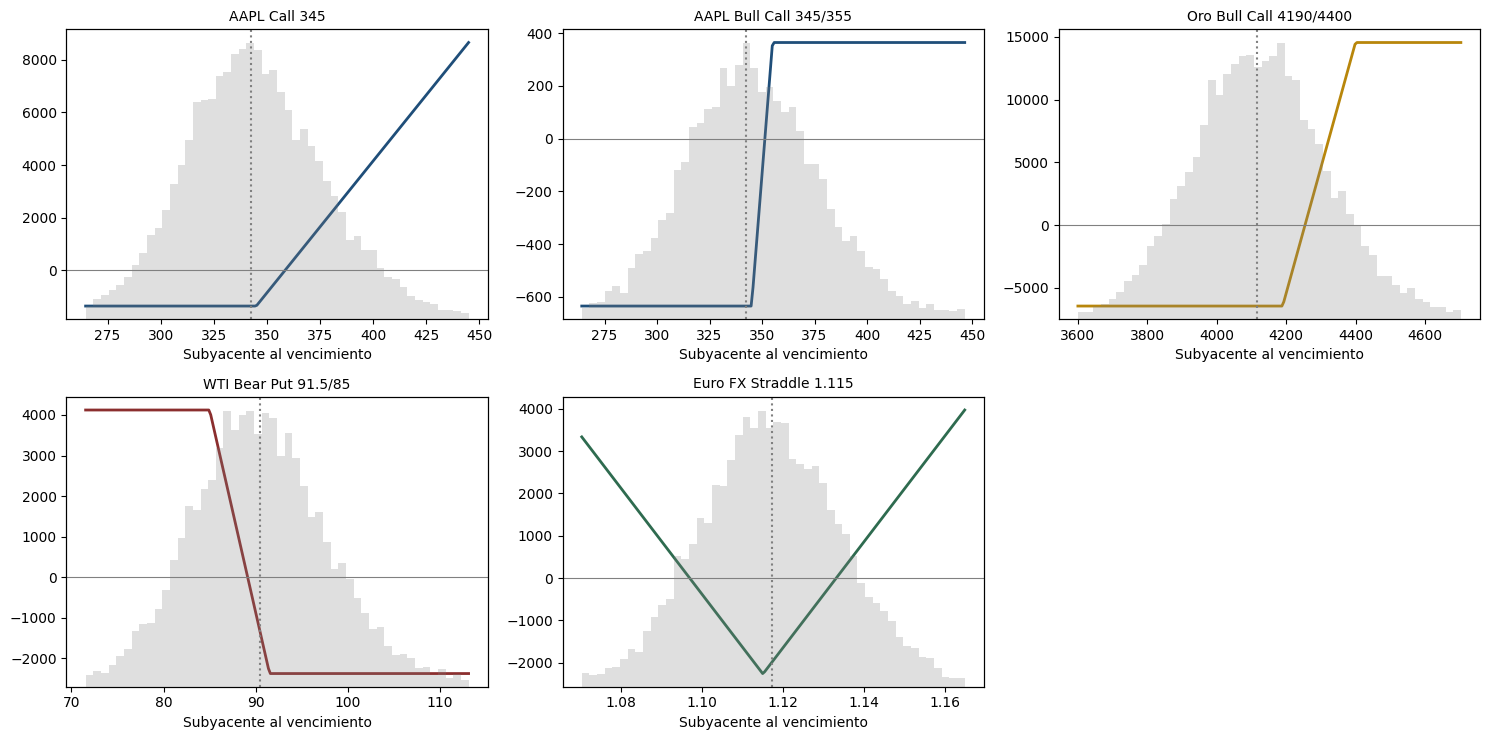


=== AAPL Call 345 (40 días) ===
σ GARCH 28.7% | σ implícita 27.2% | razón 1.05 → Sin ventaja clara: GARCH y el mercado coinciden
Prima neta pagada 13.5000 por unidad; valor hoy (σ IV) 11.7258; resultado a mercado USD -177 por contrato
Al vencimiento según GARCH: resultado esperado USD -46, probabilidad de ganar 31.9%

=== AAPL Bull Call 345/355 (40 días) ===
σ GARCH 28.7% | σ implícita 27.2% | razón 1.05 → Sin ventaja clara: GARCH y el mercado coinciden
Prima neta pagada 6.3513 por unidad; valor hoy (σ IV) 4.5771; resultado a mercado USD -177 por contrato
Al vencimiento según GARCH: resultado esperado USD -205, probabilidad de ganar 41.5%

=== Oro Bull Call 4190/4400 (16 días) ===
σ GARCH 23.4% | σ implícita 20.3% | razón 1.15 → Opciones baratas según GARCH: favorece comprar volatilidad
Prima neta pagada 64.5700 por unidad; valor hoy (σ IV) 33.2764; resultado a mercado USD -3,129 por contrato
Al vencimiento según GARCH: resultado esperado USD -2,242, probabilidad de ganar 24.6%

=== W

In [16]:
rng = np.random.default_rng(SEED + 2)
ESTRATEGIAS = {}
fig, axs = plt.subplots(2, 3, figsize=(15, 7.5)); axs = axs.ravel()
for ax, (nombre, g) in zip(axs, patas.groupby("estrategia", sort=False)):
    activo = g["activo"].iloc[0]; H = int(g["dias_hab"].iloc[0]); mult = g["mult"].iloc[0]
    ST = simular_conjunto(H, N_SIM * 2, MU_ANUAL, rng, nombres=[activo])[activo][-1]
    def pago(S):
        tot = 0
        for _, f in g.iterrows():
            tot = tot + f["pos"] * (np.maximum(S - f["K"], 0) if f["tipo"] == "call" else np.maximum(f["K"] - S, 0))
        return tot
    costo = float((g["pos"] * g["prima"]).sum())                     # positivo = débito pagado
    valor_iv = float(sum(f["pos"] * crr(f["S"], f["K"], R_FREE, f["iv"], f["T"], N_ARBOL, f["tipo"], True, f["q"])[0] for _, f in g.iterrows()))
    valor_garch = float(sum(f["pos"] * crr(f["S"], f["K"], R_FREE, f["vol_garch"], f["T"], N_ARBOL, f["tipo"], True, f["q"])[0] for _, f in g.iterrows()))
    pnl = (pago(ST) - costo) * mult
    larga = g[g["pos"] > 0].iloc[0]
    ratio = larga["vol_garch"] / larga["iv"]
    if ratio > 1 + UMBRAL_SENAL:
        senal = "Opciones baratas según GARCH: favorece comprar volatilidad"
    elif ratio < 1 - UMBRAL_SENAL:
        senal = "Opciones caras según GARCH: favorece vender volatilidad o usar spreads"
    else:
        senal = "Sin ventaja clara: GARCH y el mercado coinciden"
    grid = np.linspace(np.percentile(ST, 0.5), np.percentile(ST, 99.5), 200)
    ESTRATEGIAS[nombre] = dict(
        activo=activo, dias=int(g["dias_nat"].iloc[0]), mult=float(mult), costo=costo,
        valor_hoy_iv=valor_iv, valor_hoy_garch=valor_garch, mtm_usd=(valor_iv - costo) * mult,
        sigma_garch=float(larga["vol_garch"]), sigma_iv=float(larga["iv"]), ratio=float(ratio), senal=senal,
        pnl_esperado=float(pnl.mean()), prob_ganancia=float((pnl > 0).mean()),
        pnl_p5=float(np.percentile(pnl, 5)), pnl_p95=float(np.percentile(pnl, 95)),
        perfil=dict(S=grid.tolist(), pnl=((pago(grid) - costo) * mult).tolist()),
        hist=np.histogram(ST, bins=50, range=(grid[0], grid[-1]))[0].tolist(),
        patas=[dict(pos=int(f["pos"]), tipo=f["tipo"], K=float(f["K"]), iv=float(f["iv"]), prima=float(f["prima"]),
                    vol_garch=float(f["vol_garch"]), vol_hist=float(f["vol_hist"]), iv_origen=f["iv_origen"],
                    S=float(f["S"]), T=float(f["T"]), q=float(f["q"]), venc=f["venc"].strftime("%Y-%m-%d"),
                    futuro=bool(ES_FUTURO[activo])) for _, f in g.iterrows()])
    ax.plot(grid, (pago(grid) - costo) * mult, color=COLORES[activo], lw=2)
    ax.axhline(0, color="gray", lw=0.8); ax.axvline(S0[activo], color="gray", ls=":")
    ax2 = ax.twinx(); ax2.hist(ST, bins=50, range=(grid[0], grid[-1]), color="gray", alpha=0.25, density=True); ax2.set_yticks([])
    ax.set_title(nombre, fontsize=10); ax.set_xlabel("Subyacente al vencimiento")
for ax in axs[len(ESTRATEGIAS):]:
    ax.axis("off")
mostrar("06_estrategias")

for nombre, e in ESTRATEGIAS.items():
    print(f"\n=== {nombre} ({e['dias']} días) ===")
    print(f"σ GARCH {e['sigma_garch']:.1%} | σ implícita {e['sigma_iv']:.1%} | razón {e['ratio']:.2f} → {e['senal']}")
    print(f"Prima neta pagada {e['costo']:.4f} por unidad; valor hoy (σ IV) {e['valor_hoy_iv']:.4f}; "
          f"resultado a mercado USD {e['mtm_usd']:,.0f} por contrato")
    print(f"Al vencimiento según GARCH: resultado esperado USD {e['pnl_esperado']:,.0f}, probabilidad de ganar {e['prob_ganancia']:.1%}")

## 13. Resumen y exportación para el dashboard
- **GARCH y árbol:** el árbol valúa la opción; GARCH dice qué volatilidad usar durante su vida.
- **Pronóstico:** el Monte Carlo con GARCH da una distribución de precios, no un punto.
- **Riesgo:** el back testing verifica que el modelo no subestime las pérdidas, y el VaR del portafolio incorpora correlaciones.
- **Limitaciones:** GARCH(1,1) supone normalidad y no captura la asimetría (GJR-GARCH o EGARCH sí); los futuros continuos
  tienen saltos por cambio de contrato; las primas de las capturas son de su fecha. Con datos simulados las cifras no son de mercado.

La última celda guarda `resultados_garch.json`. En Colab se descarga solo; súbanlo al dashboard con el botón *Cargar resultados*.

In [17]:
def semanal(serie, n_max=270):
    s = serie.dropna()
    paso = max(1, len(s) // n_max)
    s = s.iloc[::paso]
    return {"f": [d.strftime("%Y-%m-%d") for d in s.index], "v": [round(float(x), 5) for x in s.values]}

def limpio(x):
    if isinstance(x, dict):
        return {str(k): limpio(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [limpio(v) for v in x]
    if isinstance(x, (np.floating, float)):
        return None if not np.isfinite(x) else round(float(x), 6)
    if isinstance(x, (np.integer,)):
        return int(x)
    return x

salida = {
    "meta": {"fuente": fuente, "sintetico": SINTETICO, "fecha_valuacion": str(FECHA_VAL.date()),
             "generado": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"), "r": R_FREE, "fedwatch": FEDWATCH,
             "tasa_esperada_dic": tasa_esperada_dic, "lambda": LAMBDA_EWMA, "n_sim": N_SIM, "horizonte": HORIZON_DAYS,
             "mu": MU_ANUAL, "years": YEARS},
    "activos": {},
    "comparacion": comparacion.to_dict("records"),
    "backtest": bt.to_dict("records"),
    "corr_hoy": CORR_HOY.round(4).to_dict(),
    "corr_series": {k: semanal(v) for k, v in CORR_SERIES.items()},
    "portafolio": {"pesos": PESOS.to_dict(), "montos": MONTOS.to_dict(), "var_param": {f"{k:.0%}": v for k, v in VAR_PORT.items()},
                   "var_mc": VAR_MC, "beneficio_div": beneficio_div, "cobertura_nq": COBERTURA},
    "patas": tabla_patas.to_dict("records"),
    "americana": tabla_amer.to_dict("records"),
    "mc_vs_arbol": tabla_mc.to_dict("records"),
    "estrategias": ESTRATEGIAS,
}
for t in NOMBRES:
    a, b = M[t]["p"][1], M[t]["p"][2]
    pct = np.percentile(SIM[t], [5, 25, 50, 75, 95], axis=1)
    ini, vg = BT[t]["inicio"], BT[t]["var"]["GARCH(1,1)"]
    lim = -norm.ppf(0.99) * np.sqrt(vg[ini:])
    exc = M[t]["u"][ini:] < lim
    salida["activos"][t] = {
        "ticker": ACTIVOS[t], "futuro": ES_FUTURO[t], "S0": S0[t], "n_obs": int(len(M[t]["u"])),
        "omega": M[t]["p"][0], "alpha": a, "beta": b, "persistencia": a + b, "vida_media": float(np.log(0.5) / np.log(a + b)),
        "vol_lp": float(vol_anual_desde_var(M[t]["VL"])), "vol_hoy": float(vol_anual_desde_var(M[t]["v_next"])),
        "vol_hist_1a": VOL_HIST_1A[t], "lam_opt": M[t]["lam_opt"], "lb_crudo": LB_CRUDO[t], "arch": ARCH_CHECK.get(t),
        "v_next": float(M[t]["v_next"]), "VL": float(M[t]["VL"]),
        "precio": semanal(precios[t]),
        "vol_hist30": semanal(VOL30[t]),
        "vol_ewma": semanal(pd.Series(vol_anual_desde_var(var_ewma(M[t]["u"])), index=REND[t].index)),
        "vol_garch": semanal(pd.Series(vol_anual_desde_var(M[t]["v"]), index=REND[t].index)),
        "estructura": [float(x) for x in vol_anual_desde_var(pron_var(M[t]["p"], M[t]["u"], M[t]["v"], 252))],
        "vol_prom": {str(d): vol_promedio(t, d) for d in plazos},
        "abanico": {k: pct[i][::3].tolist() for i, k in enumerate(["p5", "p25", "p50", "p75", "p95"])},
        "mc": resumen_mc[t],
        "bt_serie": {"f": [d.strftime("%Y-%m-%d") for d in REND[t].index[ini:]], "u": M[t]["u"][ini:].round(3).tolist(),
                     "lim": lim.round(3).tolist()},
        "bt_exc": int(exc.sum()), "bt_n": int(len(exc)),
    }

with open("resultados_garch.json", "w", encoding="utf-8") as fh:
    json.dump(limpio(salida), fh, ensure_ascii=False)
print("Archivo guardado: resultados_garch.json", f"({os.path.getsize('resultados_garch.json') / 1024:.0f} KB)")

try:
    from google.colab import files
    files.download("resultados_garch.json")
except Exception:
    pass

print("\nRESUMEN ·", fuente, "· valuación", FECHA_VAL.date())
for t in NOMBRES:
    d = salida["activos"][t]
    print(f"{t:7s} α={d['alpha']:.3f} β={d['beta']:.3f} persistencia={d['persistencia']:.3f} · vol hoy {d['vol_hoy']:.1%} → "
          f"largo plazo {d['vol_lp']:.1%} · mediana a {HORIZON_DAYS} días {resumen_mc[t]['Mediana']:.2f}")
for nombre, e in ESTRATEGIAS.items():
    print(f"{nombre:26s} {e['senal']} · P&L esperado USD {e['pnl_esperado']:,.0f} · prob. de ganar {e['prob_ganancia']:.0%}")

Archivo guardado: resultados_garch.json (355 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


RESUMEN · Yahoo Finance (yfinance) · valuación 2026-11-08
AAPL    α=0.062 β=0.903 persistencia=0.965 · vol hoy 29.0% → largo plazo 27.9% · mediana a 126 días 351.11
Oro     α=0.071 β=0.915 persistencia=0.986 · vol hoy 23.5% → largo plazo 20.8% · mediana a 126 días 4194.92
WTI     α=0.089 β=0.891 persistencia=0.980 · vol hoy 54.9% → largo plazo 43.0% · mediana a 126 días 84.78
EURUSD  α=0.042 β=0.949 persistencia=0.991 · vol hoy 5.6% → largo plazo 7.6% · mediana a 126 días 1.12
NQ      α=0.084 β=0.894 persistencia=0.978 · vol hoy 34.9% → largo plazo 24.4% · mediana a 126 días 27539.88
AAPL Call 345              Sin ventaja clara: GARCH y el mercado coinciden · P&L esperado USD -46 · prob. de ganar 32%
AAPL Bull Call 345/355     Sin ventaja clara: GARCH y el mercado coinciden · P&L esperado USD -205 · prob. de ganar 42%
Oro Bull Call 4190/4400    Opciones baratas según GARCH: favorece comprar volatilidad · P&L esperado USD -2,242 · prob. de ganar 25%
WTI Bear Put 91.5/85       Sin venta